# 05 · Final evaluation, thresholds and fairness — SepsisWatch Z

Combines the predictions from `03` (XGBoost, SIRS, qSOFA) and `04` (network on the NNPA) and answers what matters clinically, **on hospital B** (never seen during training):

| Metric | Question it answers |
|---|---|
| Hourly AUROC / AUPRC | Does the model separate risky hours well? |
| Patient-level sensitivity | What % of sepsis patients got an alert in the 12 h before onset? |
| Lead time | How much extra time does the clinical team gain? |
| False alarms per patient-day | Does it cause alarm fatigue? |
| Fairness | Does it work equally across sex and age? |

**Definitions** (same for every model):
- *Sepsis onset* = first hour with `SepsisLabel = 1` + 6 h (PhysioNet shifts the label 6 h earlier).
- *Alert* = the risk crosses the threshold from below (a new episode). Staying above it the next hour is not another alert.
- *Detection* = at least one hour above the threshold between 12 h before onset and onset.
- *False alarm* = an alert in a patient who never developed sepsis.

Thresholds are chosen **on validation only (hospital A)** and applied unchanged to hospital B.

## 1. Environment and configuration

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

MODEL_DIR   = os.path.expanduser("~/shared/sepsis/models")
REPO        = os.path.abspath("..")                            # notebooks run from notebooks/
FIG_DIR     = f"{REPO}/docs/figures"
LABEL_COL   = "SepsisLabel"

ONSET_OFFSET  = 6      # onset = first labeled hour + 6
WINDOW        = 12     # hours before onset in which an alert counts as a detection
MAX_FA_CRIT   = 1.0    # max false alarms per patient-day for Critical (team plan)
MAX_FA_WATCH  = 3.0    # max for Watch
W_XGB, W_MLP  = 0.5, 0.5
os.makedirs(FIG_DIR, exist_ok=True)

## 2. Merge predictions and build the ensemble

In [2]:
px = pd.read_pickle(f"{MODEL_DIR}/preds_xgb.pkl")
keys = ["patient_id", "hour"]
d = px.copy()
if os.path.exists(f"{MODEL_DIR}/preds_mlp.pkl"):
    pm = pd.read_pickle(f"{MODEL_DIR}/preds_mlp.pkl")
    MLP_COL = "p_mlp_nnpa" if "p_mlp_nnpa" in pm.columns else "p_mlp_cpu"
    if MLP_COL != "p_mlp_nnpa":
        warnings.warn("No NNPA predictions found: using the CPU MLP.")
    d = d.merge(pm[keys + [MLP_COL]], on=keys, how="inner", validate="1:1")
    assert len(d) == len(px), f"Rows from 03 and 04 do not match ({len(px):,} vs {len(d):,}): check the split"
    d["p_mlp"] = d[MLP_COL]
    d["p_ens"] = W_XGB * d.p_xgb + W_MLP * d.p_mlp
else:
    warnings.warn("preds_mlp.pkl not found: evaluating XGBoost only.")
    MLP_COL = None

MODELS = {"SIRS ≥ 2": "sirs", "qSOFA ≥ 2": "qsofa", "XGBoost": "p_xgb"}
if MLP_COL:
    MODELS.update({"NNPA network": "p_mlp", "Ensemble": "p_ens"})
FIXED = {"SIRS ≥ 2": 2, "qSOFA ≥ 2": 2}       # clinical rules: fixed threshold

def prepare(t):
    t = t.sort_values(["patient_id", "hour"]).reset_index(drop=True)
    first = t[t[LABEL_COL] == 1].groupby("patient_id")["hour"].min()
    t["onset"] = t["patient_id"].map(first + ONSET_OFFSET)
    t["septic"] = t["onset"].notna()
    t["in_window"] = t.septic & (t.hour >= t.onset - WINDOW) & (t.hour < t.onset)
    for col in MODELS.values():
        t[f"prev_{col}"] = t.groupby("patient_id")[col].shift()
    return t

data = {s: prepare(d[d.split == s]) for s in ("val", "test")}
for s, t in data.items():
    n_sep = t.loc[t.septic, "patient_id"].nunique(); n_eval = t.loc[t.in_window, "patient_id"].nunique()
    print(f"{s:>4}: {t.patient_id.nunique():,} patients | with sepsis {n_sep:,} (evaluable in window: {n_eval:,}) | "
          f"{(~t.septic).sum()/24:,.0f} non-sepsis patient-days")

 val: 4,067 patients | with sepsis 358 (evaluable in window: 358) | 5,742 non-sepsis patient-days
test: 20,000 patients | with sepsis 1,142 (evaluable in window: 1,142) | 28,940 non-sepsis patient-days


## 3. Evaluation functions

In [3]:
def evaluate(t, col, thr):
    s = t[col].to_numpy()
    alarm = s >= thr
    prev = t[f"prev_{col}"].to_numpy()
    rising = alarm & ~(prev >= thr)                      # new episode (NaN previous -> True if alarm)
    ns = ~t.septic.to_numpy()
    fa_day = rising[ns].sum() / max(ns.sum() / 24, 1e-9)
    det = t.loc[alarm & t.in_window.to_numpy()].groupby("patient_id")["hour"].min()
    evaluable = t.loc[t.in_window, "patient_id"].nunique()
    onset = t.groupby("patient_id")["onset"].first()
    lead = (onset.loc[det.index] - det)
    return {"sensitivity": len(det) / max(evaluable, 1), "detected": len(det), "evaluable": evaluable,
            "lead_time_median_h": float(lead.median()) if len(lead) else np.nan,
            "lead_time_p25_h": float(lead.quantile(.25)) if len(lead) else np.nan,
            "false_alarms_per_day": fa_day}

def choose_threshold(t, col, max_fa):
    grid = np.unique(np.quantile(t[col].to_numpy(), np.linspace(0.5, 0.9995, 200)))
    res = pd.DataFrame([dict(evaluate(t, col, g), threshold=g) for g in grid])
    ok = res[res.false_alarms_per_day <= max_fa]
    if ok.empty:
        warnings.warn(f"{col}: no threshold meets {max_fa} false alarms/day; using the highest one")
        return float(res.threshold.max()), res
    return float(ok.sort_values(["sensitivity", "threshold"], ascending=[False, True]).iloc[0].threshold), res

## 4. Thresholds chosen on validation (hospital A)

In [4]:
THRESHOLDS = {}
for name, col in MODELS.items():
    THRESHOLDS[name] = FIXED[name] if name in FIXED else choose_threshold(data["val"], col, MAX_FA_CRIT)[0]

MAIN, MAIN_COL = ("Ensemble", "p_ens") if MLP_COL else ("XGBoost", "p_xgb")
WATCH = min(choose_threshold(data["val"], MAIN_COL, MAX_FA_WATCH)[0], THRESHOLDS[MAIN])

val_tab = pd.DataFrame([dict(model=n, threshold=THRESHOLDS[n], **evaluate(data["val"], c, THRESHOLDS[n])) for n, c in MODELS.items()])
display(val_tab.style.format({"threshold": "{:.4f}", "sensitivity": "{:.1%}", "lead_time_median_h": "{:.1f}",
                              "lead_time_p25_h": "{:.1f}", "false_alarms_per_day": "{:.2f}"}))
print(f"Watch threshold: {WATCH:.4f} (≤ {MAX_FA_WATCH} false alarms per patient-day on validation)")

,model,threshold,sensitivity,detected,evaluable,lead_time_median_h,lead_time_p25_h,false_alarms_per_day
0,SIRS ≥ 2,2.0000,76.0%,272,358,11.0,6.0,1.72
1,qSOFA ≥ 2,2.0000,23.2%,83,358,7.0,4.0,0.55
2,XGBoost,0.3119,93.9%,336,358,12.0,10.0,0.97
3,NNPA network,0.5684,74.9%,268,358,12.0,9.0,1.00
4,Ensemble,0.4480,83.5%,299,358,12.0,8.0,1.00


Watch threshold: 0.2965 (≤ 3.0 false alarms per patient-day on validation)


## 5. Final results on hospital B (evidence 20)

,AUROC_hourly,AUPRC_hourly,sensitivity,detected,evaluable,lead_time_median_h,false_alarms_per_day
model,,,,,,,
SIRS ≥ 2,0.665,0.028,75.0%,856,1142,11.0 h,1.32
qSOFA ≥ 2,0.578,0.018,21.8%,249,1142,7.0 h,0.35
XGBoost,0.746,0.049,84.6%,966,1142,11.0 h,1.07
NNPA network,0.711,0.046,67.3%,768,1142,11.0 h,0.83
Ensemble,0.747,0.054,70.7%,807,1142,11.0 h,0.74


Hourly prevalence in B: 0.0141 (AUPRC baseline)


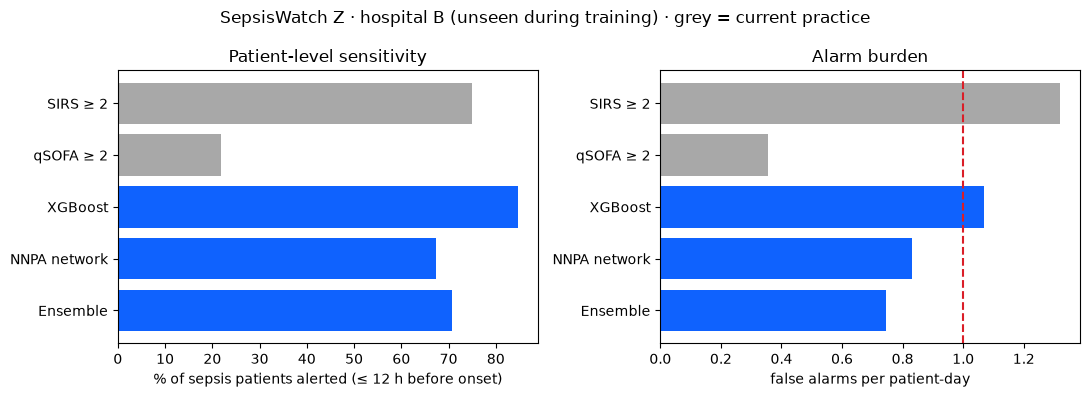

In [5]:
t = data["test"]
rows = []
for name, col in MODELS.items():
    r = evaluate(t, col, THRESHOLDS[name])
    rows.append({"model": name, "AUROC_hourly": roc_auc_score(t[LABEL_COL], t[col]),
                 "AUPRC_hourly": average_precision_score(t[LABEL_COL], t[col]), **r})
final = pd.DataFrame(rows).set_index("model")
display(final[["AUROC_hourly", "AUPRC_hourly", "sensitivity", "detected", "evaluable", "lead_time_median_h", "false_alarms_per_day"]]
        .style.format({"AUROC_hourly": "{:.3f}", "AUPRC_hourly": "{:.3f}", "sensitivity": "{:.1%}",
                       "lead_time_median_h": "{:.1f} h", "false_alarms_per_day": "{:.2f}"}))
print(f"Hourly prevalence in B: {t[LABEL_COL].mean():.4f} (AUPRC baseline)")
final.to_csv(f"{MODEL_DIR}/results_hospital_B.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#a8a8a8" if n in FIXED else "#0f62fe" for n in final.index]
ax[0].barh(final.index[::-1], final.sensitivity[::-1] * 100, color=colors[::-1])
ax[0].set_xlabel("% of sepsis patients alerted (≤ 12 h before onset)"); ax[0].set_title("Patient-level sensitivity")
ax[1].barh(final.index[::-1], final.false_alarms_per_day[::-1], color=colors[::-1])
ax[1].axvline(MAX_FA_CRIT, ls="--", color="#da1e28"); ax[1].set_xlabel("false alarms per patient-day"); ax[1].set_title("Alarm burden")
fig.suptitle("SepsisWatch Z · hospital B (unseen during training) · grey = current practice")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/results_hospital_B.png", dpi=150); plt.show()

## 6. Dashboard level distribution (hospital B)

In [6]:
sc = t[MAIN_COL]
level = np.select([sc >= THRESHOLDS[MAIN], sc >= WATCH], ["Critical", "Watch"], "Stable")
print(pd.Series(level).value_counts(normalize=True).reindex(["Critical", "Watch", "Stable"]).fillna(0).map("{:.1%}".format).to_string())

Critical    17.3%
Watch       22.9%
Stable      59.8%


## 7. Fairness by sex and age (evidence 21)
Sensitivity and false alarms of the main model on hospital B, per group. `Gender`: 0 = female, 1 = male (PhysioNet coding).

,dimension,group,patients,evaluable,sensitivity,lead_time_median_h,false_alarms_per_day
0,Sex,Female,9268,495,71.5%,11.0 h,0.70
1,Sex,Male,10732,647,70.0%,11.0 h,0.78
2,Age group,< 45,3387,200,67.0%,9.5 h,0.75
3,Age group,45–64,7709,427,71.2%,11.0 h,0.73
4,Age group,65–79,6582,386,72.5%,11.0 h,0.76
5,Age group,≥ 80,2322,129,69.0%,10.0 h,0.73


Largest sensitivity gap between groups: {'Age group': '5.5%', 'Sex': '1.5%'}


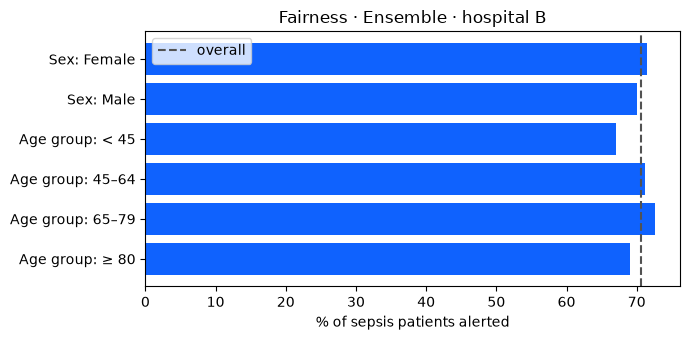

In [7]:
pat = t.groupby("patient_id").agg(Age=("Age", "first"), Gender=("Gender", "first"))
pat["Sex"] = pat.Gender.map({0: "Female", 1: "Male"}).fillna("Unknown")
pat["Age group"] = pd.cut(pat.Age, [0, 45, 65, 80, 200], right=False, labels=["< 45", "45–64", "65–79", "≥ 80"])

rows = []
for dim in ("Sex", "Age group"):
    for g, ids in pat.groupby(dim, observed=True).groups.items():
        r = evaluate(t[t.patient_id.isin(ids)], MAIN_COL, THRESHOLDS[MAIN])
        rows.append({"dimension": dim, "group": g, "patients": len(ids), **r})
fairness = pd.DataFrame(rows)
display(fairness[["dimension", "group", "patients", "evaluable", "sensitivity", "lead_time_median_h", "false_alarms_per_day"]]
        .style.format({"sensitivity": "{:.1%}", "lead_time_median_h": "{:.1f} h", "false_alarms_per_day": "{:.2f}"}))
fairness.to_csv(f"{MODEL_DIR}/fairness_hospital_B.csv", index=False)
gap = fairness.groupby("dimension").sensitivity.agg(lambda s: s.max() - s.min())
print("Largest sensitivity gap between groups:", {k: f"{v:.1%}" for k, v in gap.items()})

fig, ax = plt.subplots(figsize=(7, 3.5))
labels = fairness.dimension + ": " + fairness.group.astype(str)
ax.barh(labels[::-1], fairness.sensitivity[::-1] * 100, color="#0f62fe")
ax.axvline(final.loc[MAIN, "sensitivity"] * 100, ls="--", color="#525252", label="overall")
ax.set_xlabel("% of sepsis patients alerted"); ax.set_title(f"Fairness · {MAIN} · hospital B"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fairness_hospital_B.png", dpi=150); plt.show()

## 8. Save thresholds (for the `scorer`) and `docs/results.md`

In [8]:
thr = {"model": MAIN, "weights": {"xgb": W_XGB, "mlp": W_MLP if MLP_COL else 0.0}, "mlp_column": MLP_COL,
       "critical": float(THRESHOLDS[MAIN]), "watch": float(WATCH),
       "rule": "risk = 0.5*p_xgb + 0.5*p_mlp; Critical if risk >= critical; Watch if risk >= watch; else Stable",
       "criterion": f"thresholds chosen on validation (hospital A) with ≤ {MAX_FA_CRIT} and ≤ {MAX_FA_WATCH} false alarms per patient-day"}
# Thresholds for every model, so the scorer can switch with MODEL=ensemble|xgb|mlp
KEYS = {"XGBoost": ("xgb", "p_xgb"), "NNPA network": ("mlp", "p_mlp"), "Ensemble": ("ensemble", "p_ens")}
thr["per_model"] = {}
for name, (key, col) in KEYS.items():
    if name in THRESHOLDS:
        watch_m = choose_threshold(data["val"], col, MAX_FA_WATCH)[0]
        thr["per_model"][key] = {"critical": float(THRESHOLDS[name]), "watch": float(min(watch_m, THRESHOLDS[name]))}
with open(f"{MODEL_DIR}/thresholds.json", "w") as f:
    json.dump(thr, f, indent=2, ensure_ascii=False)

def md_table(df_, cols, fmt):
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df_.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in cols) + " |")
    return "\n".join(lines)

text = f'''# Results — SepsisWatch Z

Trained on hospital A (PhysioNet 2019 set A) and evaluated on hospital B (set B), which no model saw during training.
Thresholds chosen on validation (hospital A) with at most {MAX_FA_CRIT} false alarm per patient-day.
Detection = an alert within {WINDOW} h before sepsis onset. Alert = a new episode above the threshold.

## Hospital B

{md_table(final.reset_index(), ["model", "AUROC_hourly", "AUPRC_hourly", "sensitivity", "lead_time_median_h", "false_alarms_per_day"],
          {"AUROC_hourly": "{:.3f}", "AUPRC_hourly": "{:.3f}", "sensitivity": "{:.1%}", "lead_time_median_h": "{:.1f} h", "false_alarms_per_day": "{:.2f}"})}

Hourly prevalence in hospital B: {t[LABEL_COL].mean():.4f}.

## Fairness ({MAIN}, hospital B)

{md_table(fairness, ["dimension", "group", "patients", "sensitivity", "lead_time_median_h", "false_alarms_per_day"],
          {"sensitivity": "{:.1%}", "lead_time_median_h": "{:.1f} h", "false_alarms_per_day": "{:.2f}"})}

Figures: `docs/figures/results_hospital_B.png`, `docs/figures/fairness_hospital_B.png`, `docs/figures/xgb_importance.png`, `docs/figures/latency_cpu_vs_nnpa.png`.
'''
with open(f"{REPO}/docs/results.md", "w") as f:
    f.write(text)
print("Saved thresholds.json and docs/results.md")
print(json.dumps(thr, indent=2, ensure_ascii=False))

Saved thresholds.json and docs/results.md
{
  "model": "Ensemble",
  "weights": {
    "xgb": 0.5,
    "mlp": 0.5
  },
  "mlp_column": "p_mlp_nnpa",
  "critical": 0.44798250117194127,
  "watch": 0.29653117060661316,
  "rule": "risk = 0.5*p_xgb + 0.5*p_mlp; Critical if risk >= critical; Watch if risk >= watch; else Stable",
  "criterion": "thresholds chosen on validation (hospital A) with ≤ 1.0 and ≤ 3.0 false alarms per patient-day",
  "per_model": {
    "xgb": {
      "critical": 0.3119467794895172,
      "watch": 0.3119467794895172
    },
    "mlp": {
      "critical": 0.568359375,
      "watch": 0.26220703125
    },
    "ensemble": {
      "critical": 0.44798250117194127,
      "watch": 0.29653117060661316
    }
  }
}


## 9. Pitch numbers

In [9]:
r_main, r_sirs = final.loc[MAIN], final.loc["SIRS ≥ 2"]
print(f"{MAIN} on hospital B (unseen during training):")
print(f"  · Alerts {r_main.sensitivity:.0%} of sepsis patients, with a median lead time of {r_main.lead_time_median_h:.1f} h")
print(f"  · {r_main.false_alarms_per_day:.2f} false alarms per patient-day")
print(f"SIRS ≥ 2 (current practice): {r_sirs.sensitivity:.0%} sensitivity with {r_sirs.false_alarms_per_day:.2f} false alarms per patient-day")
if r_main.false_alarms_per_day > 0:
    print(f"  → {r_sirs.false_alarms_per_day / r_main.false_alarms_per_day:.1f}x fewer false alarms than SIRS")

Ensemble on hospital B (unseen during training):
  · Alerts 71% of sepsis patients, with a median lead time of 11.0 h
  · 0.74 false alarms per patient-day
SIRS ≥ 2 (current practice): 75% sensitivity with 1.32 false alarms per patient-day
  → 1.8x fewer false alarms than SIRS
